Loading data and finding most important features...

Analyzing 10 quantum chemical descriptors.

The Top 10 Most Important Quantum Descriptors are: ['anion_Energy_Hartree', 'cation_Energy_Hartree', 'cation_LUMO_Eh', 'cation_HOMO_Eh', 'cation_HOMO_LUMO_Gap_Eh', 'anion_LUMO_Eh', 'anion_HOMO_Eh', 'anion_HOMO_LUMO_Gap_Eh', 'cation_Dipole_Moment_Debye', 'anion_Dipole_Moment_Debye']


/var/folders/1t/1v9pd23n51g3s6_ffmy89q8c0000gn/T/ipykernel_43072/4218552253.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


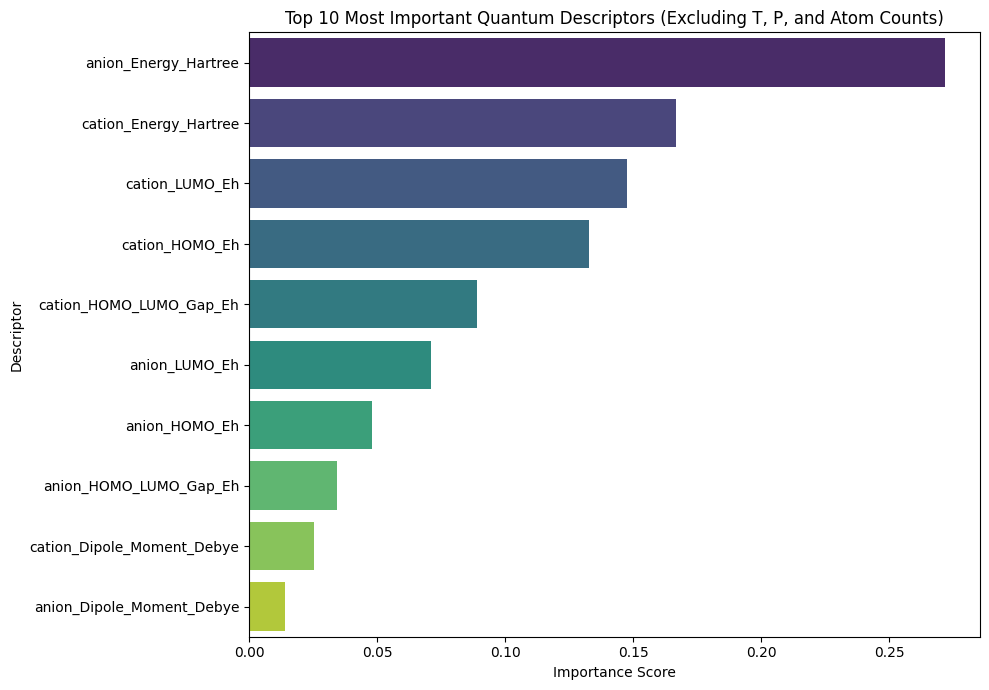

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

print("Loading data and finding most important features...")

# --- 1. Load Data ---
df = pd.read_csv("../data/final_model_dataset_v3.csv")

# --- 2. Prepare Data (to find importances) ---
ignore_cols = ["cation", "cation_ion_name", "anion", "anion_ion_name"]
target_col = "CO2_solubility"
all_feature_cols = [col for col in df.columns if col not in ignore_cols + [target_col]]

# --- NEW: Filter the list to exclude atom counts AND T/P ---
exclude_cols = ['Temperature_K', 'Pressure_kPa'] # Add T/P to the exclusion list
feature_cols = [
    col for col in all_feature_cols 
    if not col.startswith('anion_num_') 
    and not col.startswith('cation_num_')
    and col not in exclude_cols
]

print(f"\nAnalyzing {len(feature_cols)} quantum chemical descriptors.")

X = df[feature_cols] # Use the new, filtered list of features
y = df[target_col]

# --- 3. Train a Random Forest on the filtered feature set ---
model_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model_rf.fit(X, y)

# --- 4. Get the Top 10 Most Important Descriptors ---
importances = model_rf.feature_importances_
importance_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importances})

top_features_df = importance_df.sort_values(by='Importance', ascending=False).head(10)
top_feature_names = top_features_df['Feature'].tolist()

print(f"\nThe Top 10 Most Important Quantum Descriptors are: {top_feature_names}")

# --- 5. Plot the Top 10 Most Important Descriptors ---
plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_features_df,
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title("Top 10 Most Important Quantum Descriptors (Excluding T, P, and Atom Counts)")
plt.xlabel("Importance Score")
plt.ylabel("Descriptor")
plt.tight_layout()
plt.show()


Generating Pairplot for Top 6 Quantum Descriptors...


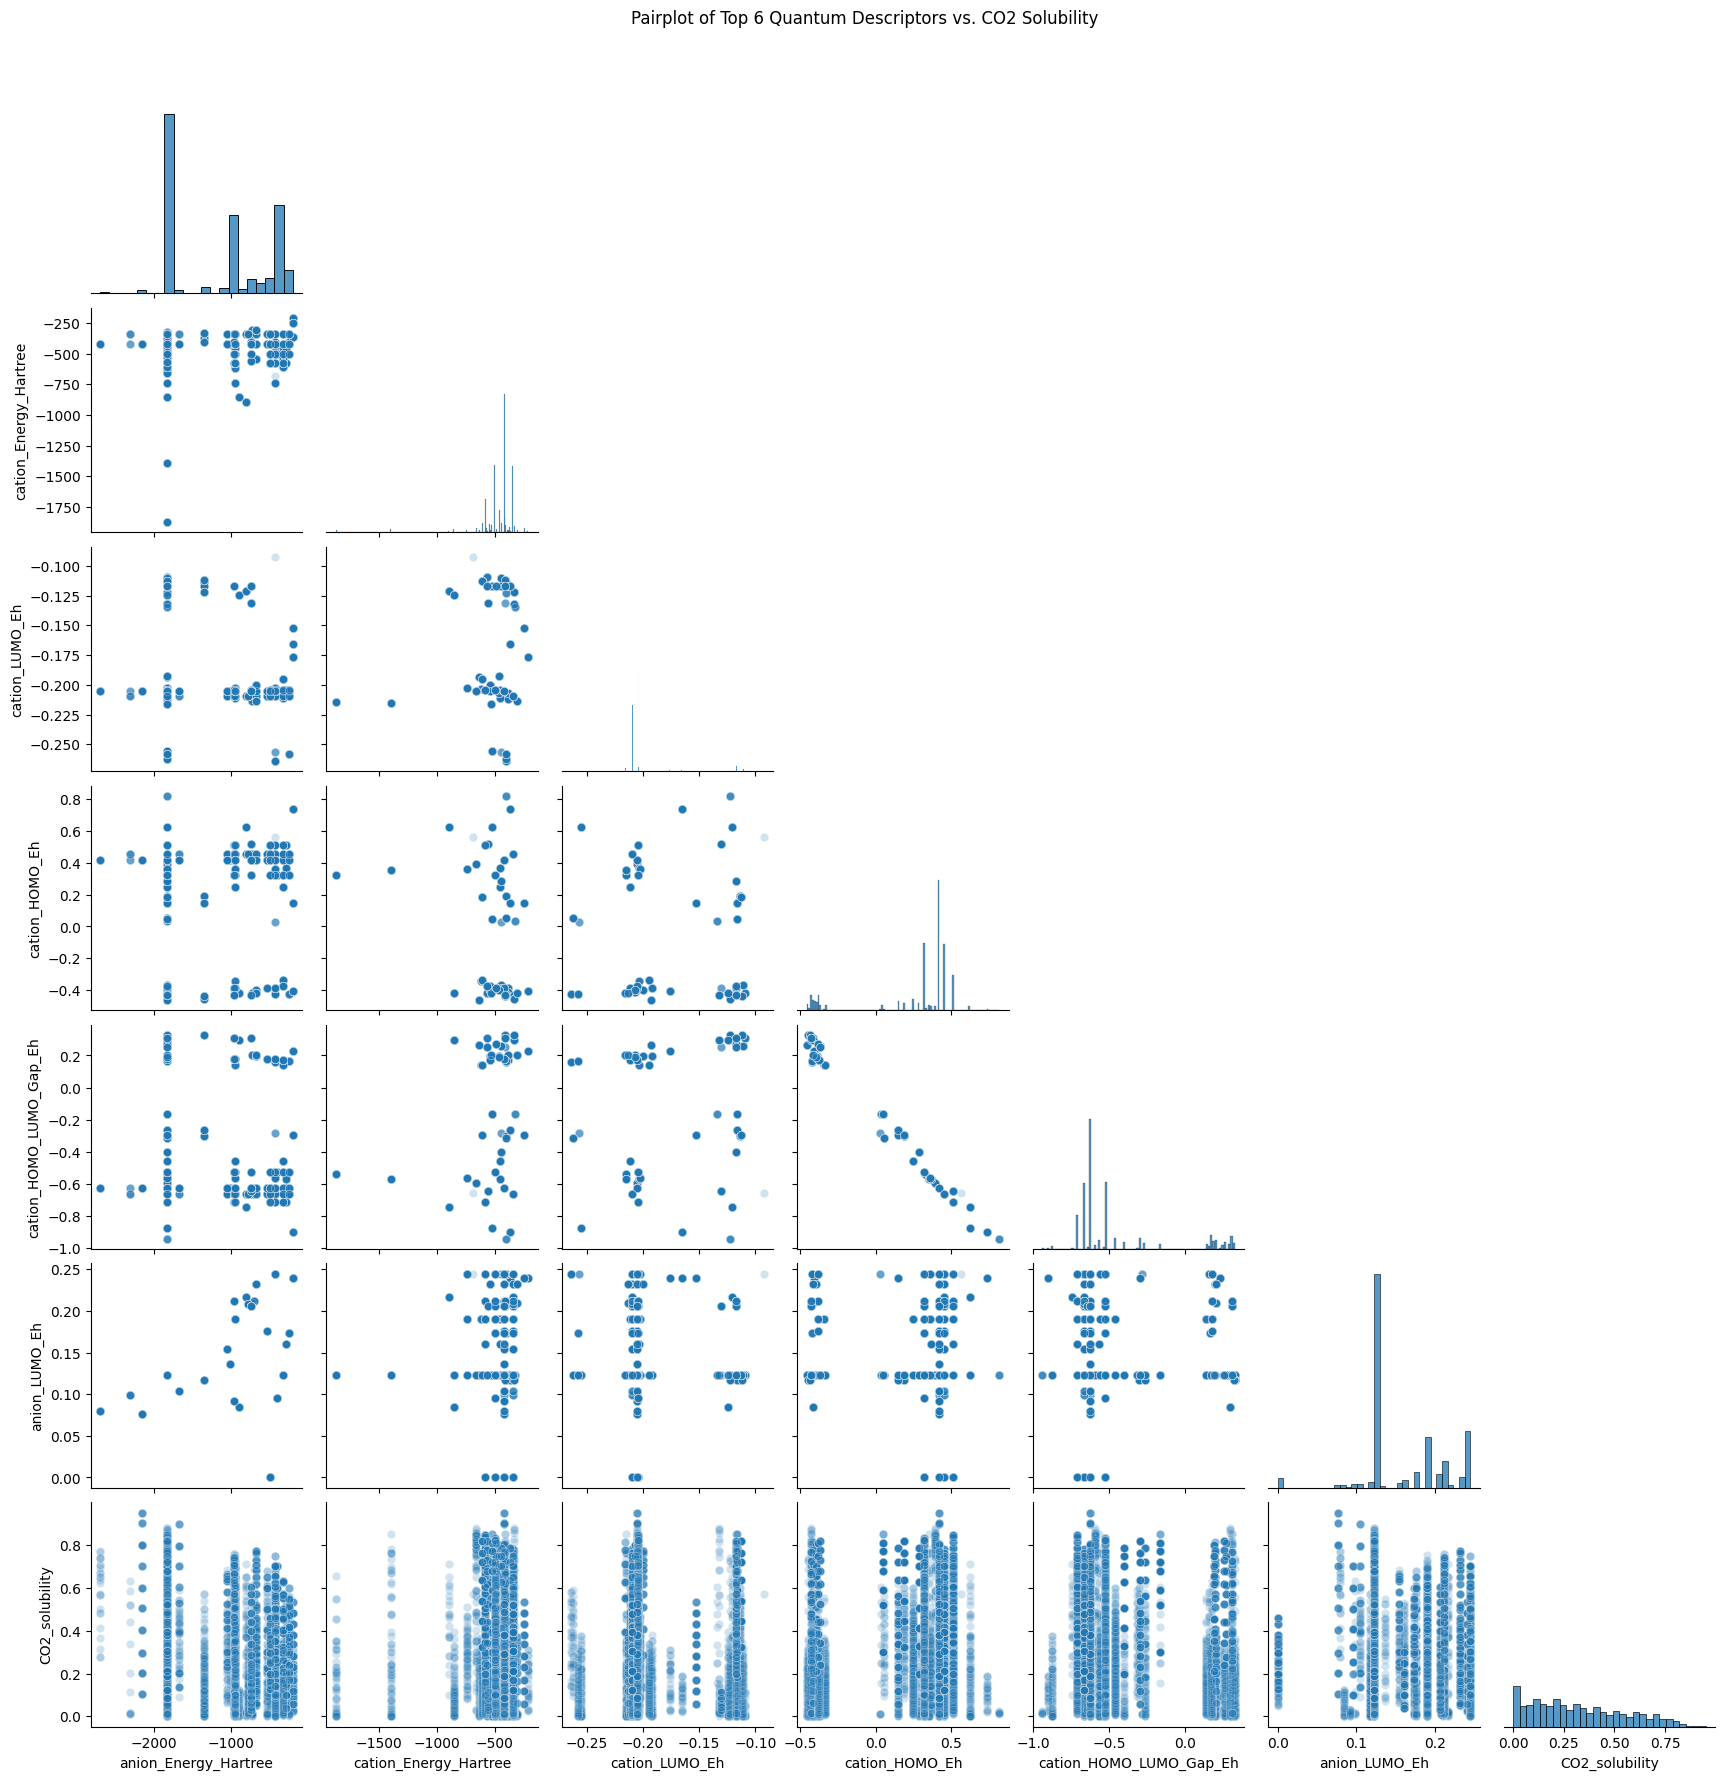

In [11]:
# Create a Pairplot for the top 6 descriptors + the target
plot_cols = top_feature_names[:6] + [target_col]

print("\nGenerating Pairplot for Top 6 Quantum Descriptors...")
g = sns.pairplot(df[plot_cols], corner=True, plot_kws={'alpha': 0.2})
g.fig.suptitle("Pairplot of Top 6 Quantum Descriptors vs. CO2 Solubility", y=1.02)
plt.show()


Generating individual regression plots for Top 10 quantum descriptors...


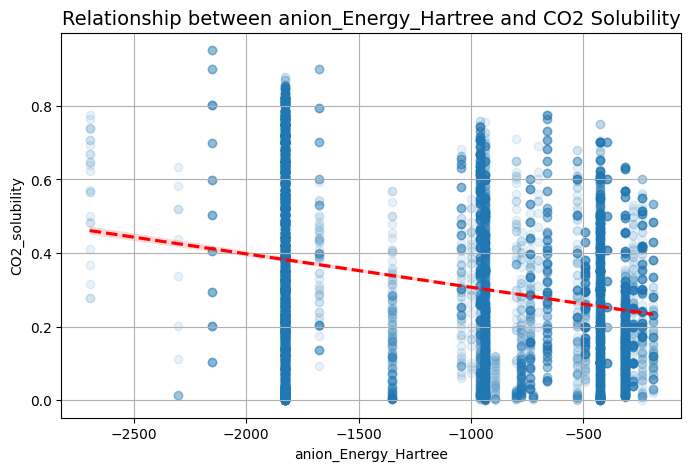

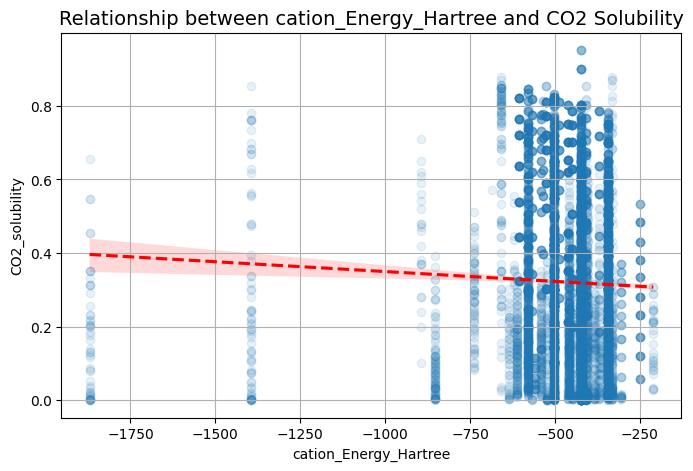

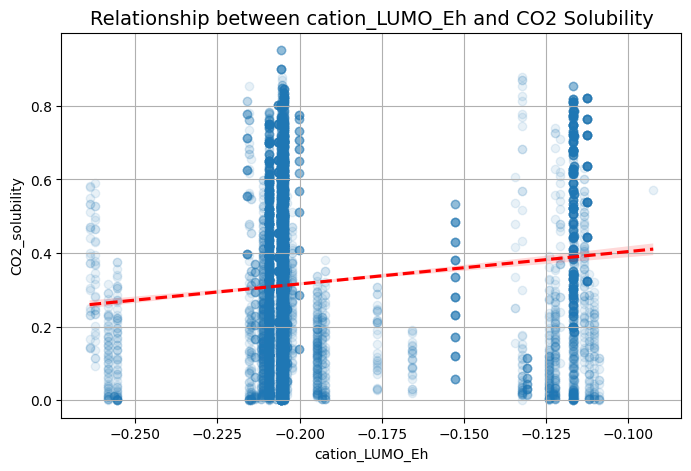

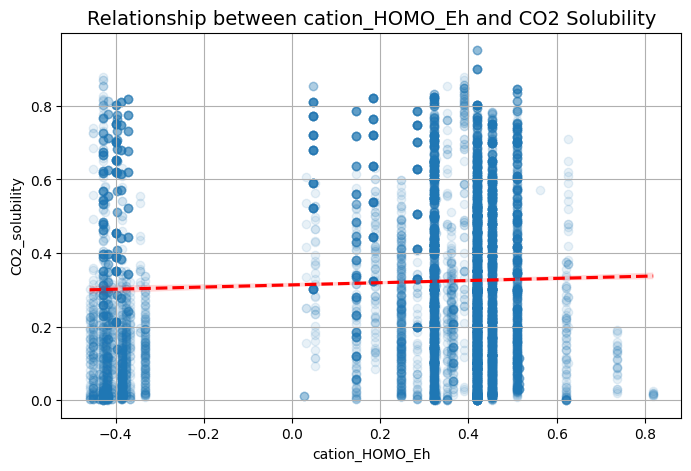

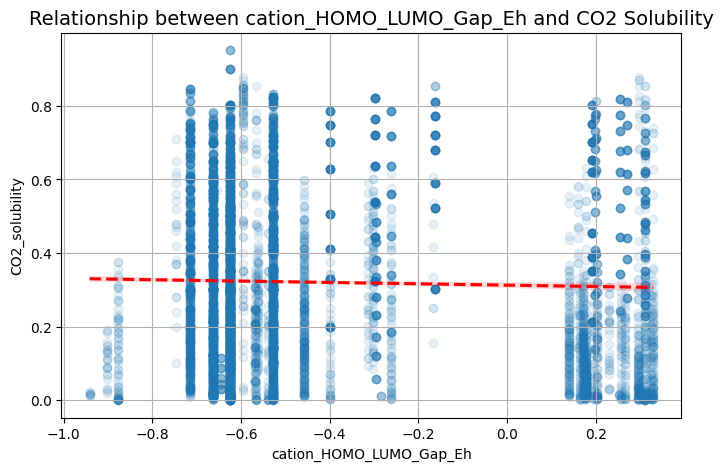

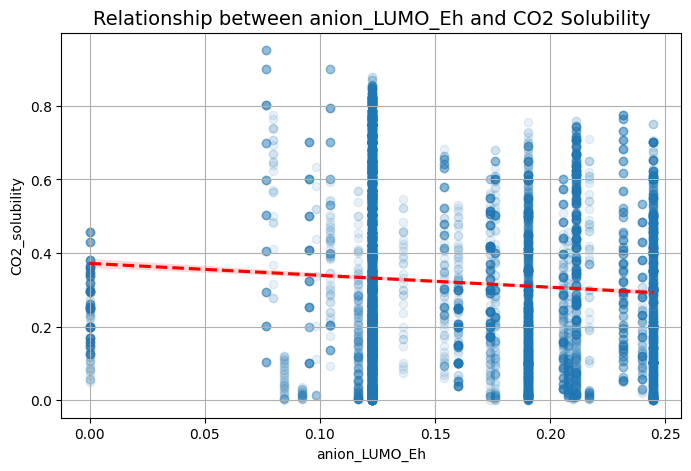

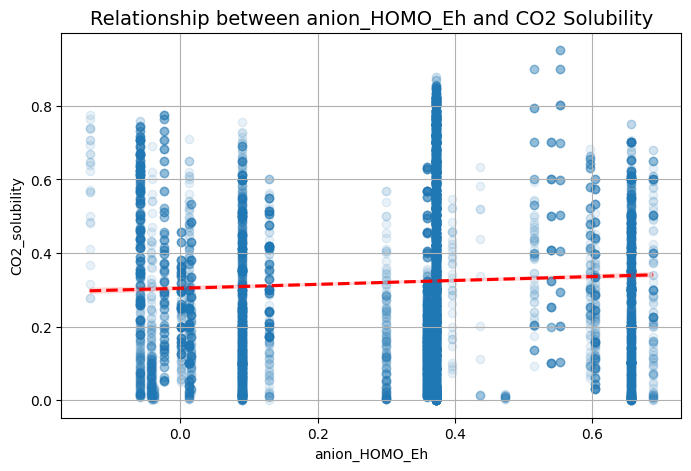

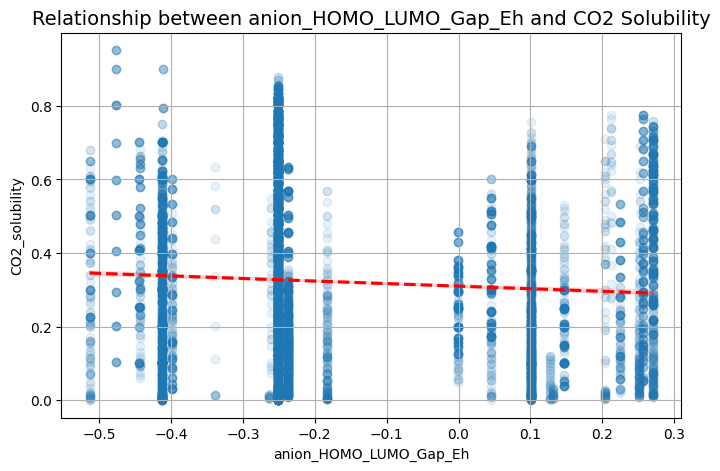

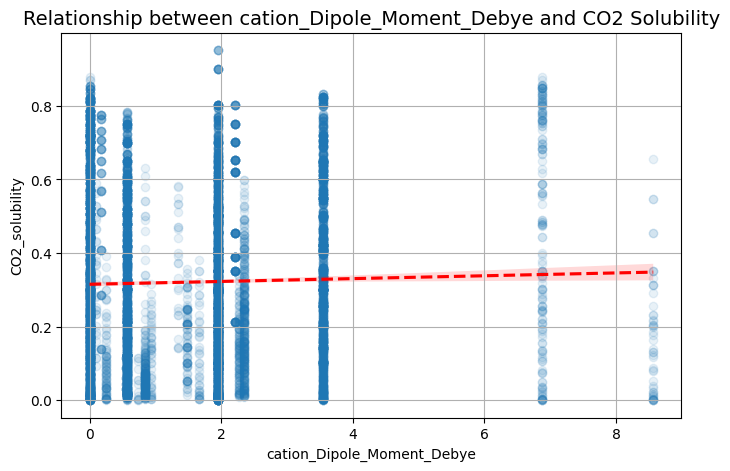

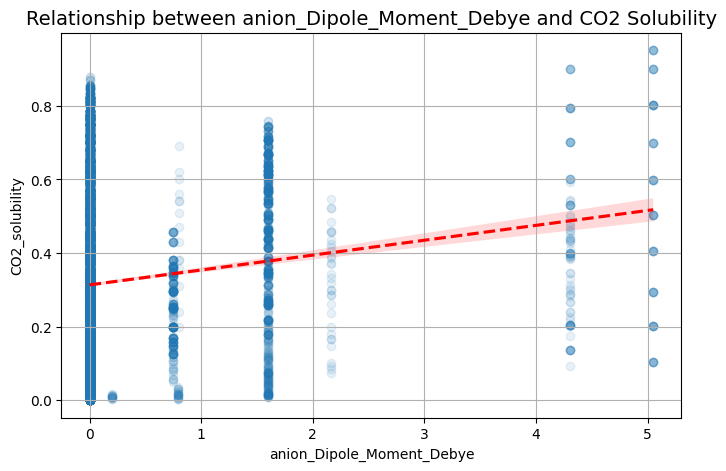

In [12]:
# Create a separate, larger plot for each of the top 10 descriptors.
print("\nGenerating individual regression plots for Top 10 quantum descriptors...")
for feature in top_feature_names: # This will loop through all 10
    plt.figure(figsize=(8, 5))
    sns.regplot(
        data=df, 
        x=feature, 
        y='CO2_solubility', 
        line_kws={'color':'red', 'linestyle':'--'}, 
        scatter_kws={'alpha': 0.1}
    )
    plt.title(f"Relationship between {feature} and CO2 Solubility", fontsize=14)
    plt.grid(True)
    plt.show()